---
title: Week 5 Challenge 2 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about density plots.

Use the notebook **Density Plots** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is `penguins`, available from Seaborn. It comes from a study of three penguin species on the Palmer Archipelago in Antarctica.

Each row is an observation for a single penguin.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| species | Categorical | Adelie, Chinstrap, Gentoo | Species of the penguin. |
| island | Categorical | Biscoe, Dream, Torgersen | Island where the penguin was observed. |
| bill_length_mm | Continuous | 32.1 – 59.6 | Length of the bill. |
| bill_depth_mm | Continuous | 13.1 – 21.5 | Depth of the bill. |
| flipper_length_mm | Continuous | 172 – 231 | Flipper length. |
| body_mass_g | Continuous | 2700 – 6300 | Body mass in grams. |
| sex | Categorical | Female, Male | Sex of the penguin. |

Note that the dataset contains a small number of missing values.

## Set Up

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
penguins = sns.load_dataset('penguins')
penguins.index.name = 'obs_id'
penguins.info()
penguins.head()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
obs_id,,,,,,,
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Tasks

### Task 1

Create a density plot of `body_mass_g`.

Describe the shape. How many populations do you think are present?

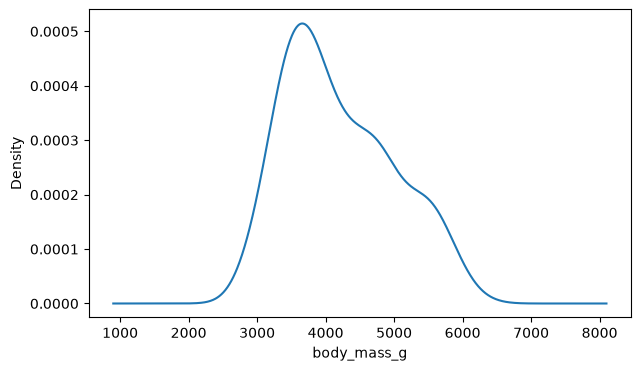

In [4]:
penguins.body_mass_g.plot.kde(figsize=(7,4))
plt.xlabel('body_mass_g')
plt.show()

**Answer**: The curve has a single clear peak near $3700$ grams, and then a shoulder on its right flank between roughly $4300$ and $5000$ grams where the descent flattens out.

The shoulder is a hint that more than one population is present, but it is only a hint. The curve has one maximum, not two, and the pooled plot cannot tell us what distinguishes the groups.

### Task 2

Build a wide table in which each column holds the body masses of one species, then plot all three density curves on the same axes.

Hint: Pivot the dataframe setting the columns to `species` and the values to `body_mass_g`. Don't worry about setting the index.

In [5]:
mass_by_species = penguins.pivot(columns='species', values='body_mass_g')
mass_by_species.sample(10).sort_index()

species,Adelie,Chinstrap,Gentoo
obs_id,,,
6,3625.0,NaN,NaN
14,4400.0,NaN,NaN
52,3450.0,NaN,NaN
61,4400.0,NaN,NaN
131,3500.0,NaN,NaN
162,NaN,3800.0,NaN
208,NaN,3250.0,NaN
229,NaN,NaN,5150.0
237,NaN,NaN,6300.0


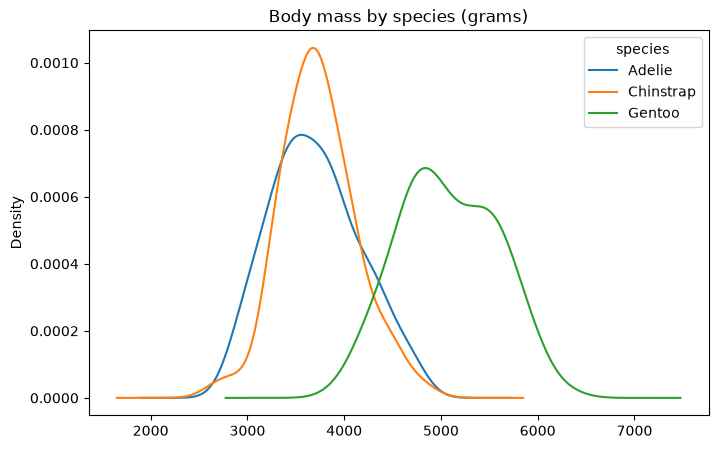

In [6]:
mass_by_species.plot.kde(figsize=(8,5))
plt.title('Body mass by species (grams)')
plt.show()

**Answer**: 

The shoulder is explained. 

Gentoo penguins are substantially heavier than the other two species, whose distributions overlap almost completely.

Adelie and Chinstrap are nearly indistinguishable by body mass alone, which is itself a useful finding.

### Task 3

Produce the same plot using Seaborn's `sns.kdeplot`, setting `hue` to `species` and filling the area under each curve.

Note that this lets you skip the reshaping step from Task 2.

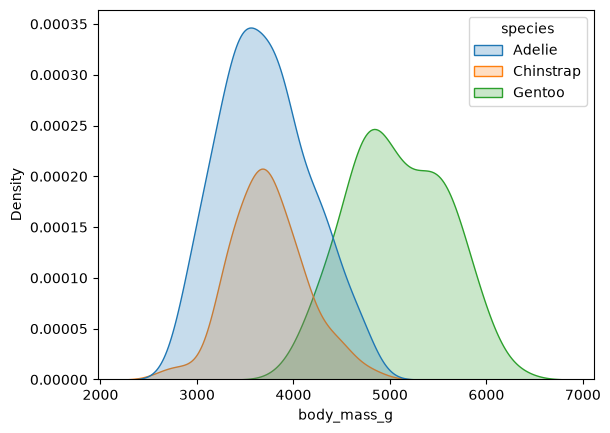

In [7]:
sns.kdeplot(penguins, x='body_mass_g', hue='species', fill=True)
plt.show()

### Task 4

Redraw the plot from Task 2 three times, using bandwidths of $0.2$, the default, and $1.5$.

What changes, and what does that tell you about claims based on this plot?

Hint: pass `bw_method` to `.plot.kde()`.

Also, display your three plots using `plt.subplots()` to start things off.

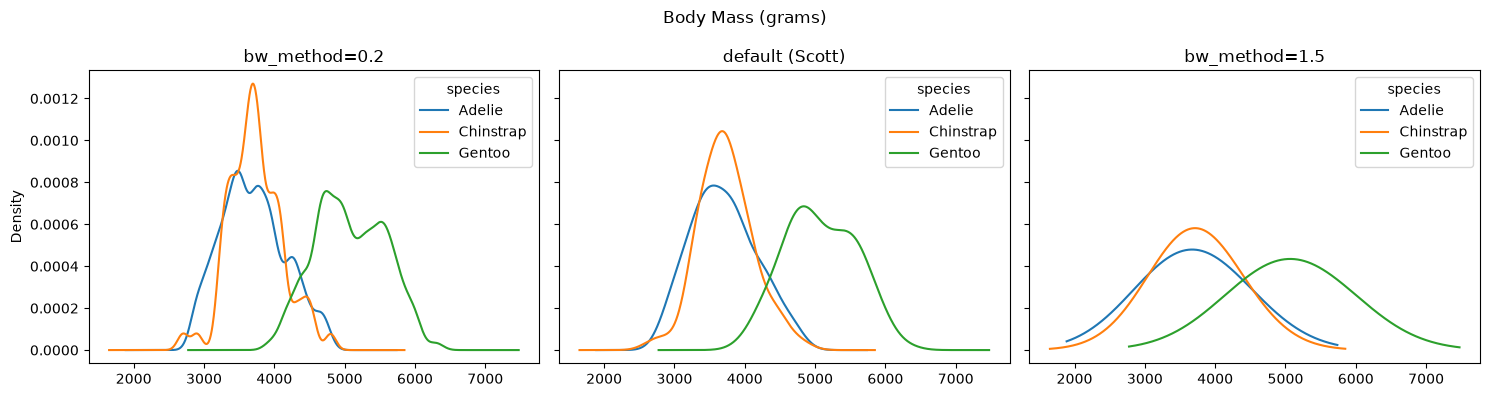

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

mass_by_species.plot.kde(ax=ax[0], bw_method=0.2, title='bw_method=0.2')
mass_by_species.plot.kde(ax=ax[1], title='default (Scott)')
mass_by_species.plot.kde(ax=ax[2], bw_method=1.5, title='bw_method=1.5')

plt.suptitle("Body Mass (grams)")
plt.tight_layout()
plt.show()

**Answer**: 

At $0.2$ each curve breaks into several bumps. 

At $1.5$ the three species merge into three broad overlapping mounds and the separation of Gentoo is weakened.

The same data supports different claims about modality depending on a parameter the analyst chose. 

Any claim about the number of modes should be accompanied by the bandwidth used.

### Task 5

Now split the data by both `species` and `sex`, and plot the resulting density curves on a single set of axes.

Hint: Use `penguins.groupby()`.

How many observations are in the smallest group?

#### Method 1

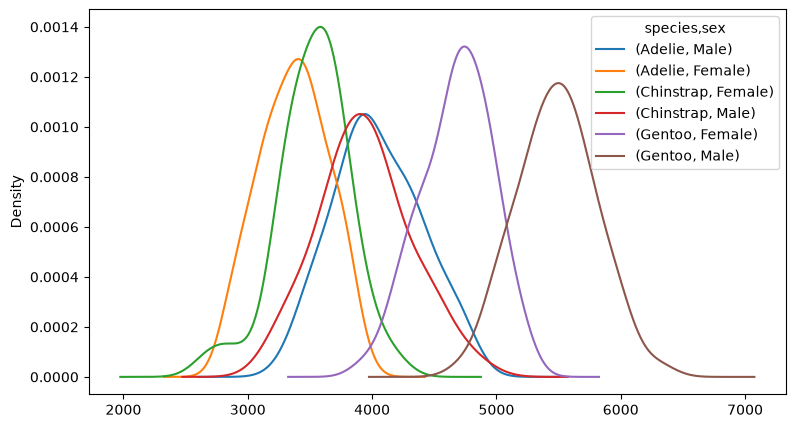

In [9]:
penguins.dropna().pivot(columns=['species','sex'], values='body_mass_g').plot.kde(figsize=(9,5))
plt.show()

#### Method 2

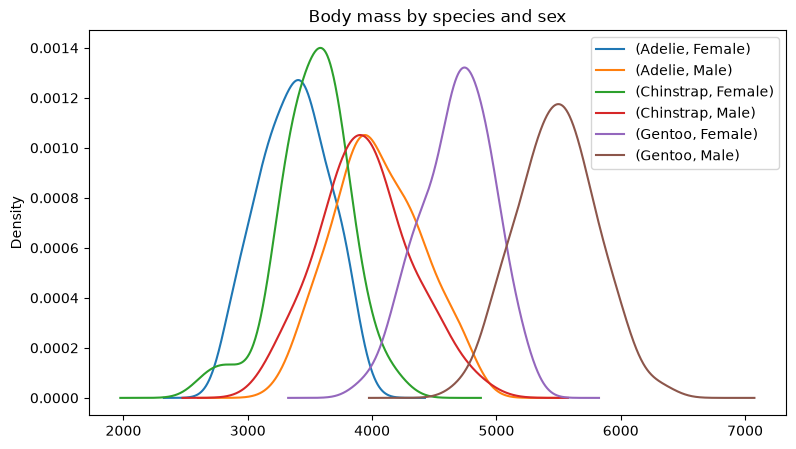

In [10]:
penguins.groupby(['species','sex']).body_mass_g.plot.kde(figsize=(9,5))
plt.title('Body mass by species and sex')
plt.legend()
plt.show()

In [11]:
penguins.value_counts(['species','sex'])

species    sex   
Adelie     Male      73
           Female    73
Gentoo     Male      61
           Female    58
Chinstrap  Female    34
           Male      34
Name: count, dtype: int64

**Answer**: The smallest groups are Chinstrap Female and Chinstrap Male, at $34$ penguins each.

Sex accounts for much of the remaining width within each species. Within every species the male curve sits to the right of the female curve.

At $n = 34$, however, we are near the point at which the shape of a density curve is governed more by the bandwidth than by the data. 

These curves should be read as rough locations, not as detailed shapes.

### Task 6

The observed range of `body_mass_g` is $2700$ to $6300$ grams.

Look at the x axis of the plot you just made. What is wrong with it?

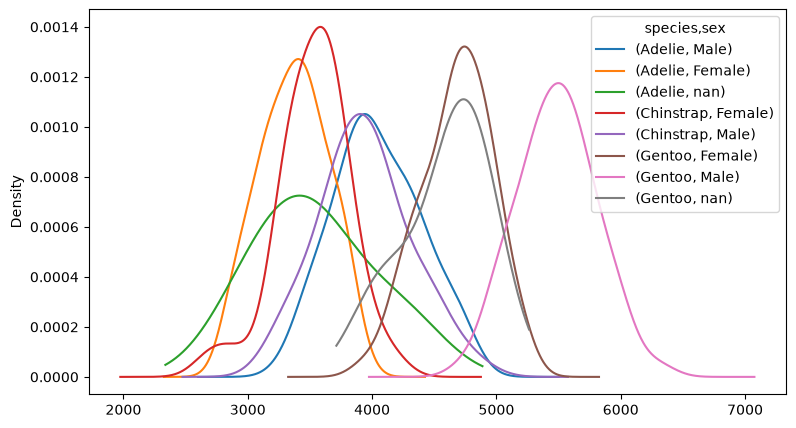

In [12]:
penguins.pivot(columns=['species','sex'], values='body_mass_g').plot.kde(figsize=(9,5))
plt.show()

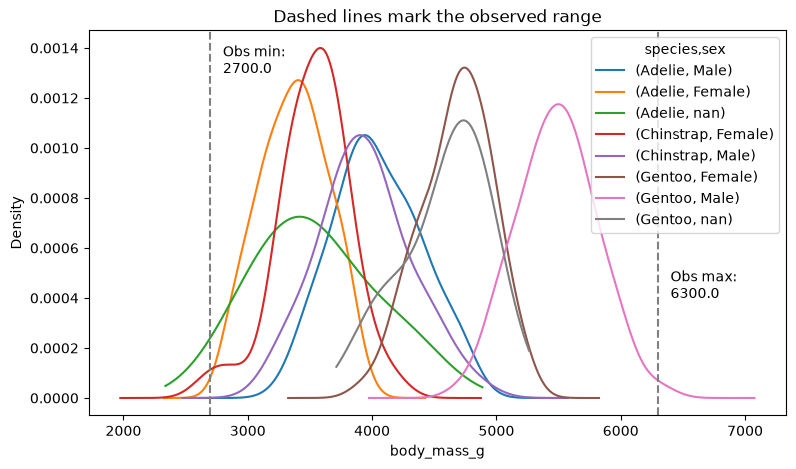

In [13]:
obs_min = penguins.body_mass_g.min()
obs_max = penguins.body_mass_g.max()

penguins1 = penguins.pivot(columns=['species','sex'], values='body_mass_g')
ax = penguins1.plot.kde(figsize=(9,5))
ax.axvline(penguins.body_mass_g.min(), ls='--', c='gray')
ax.axvline(penguins.body_mass_g.max(), ls='--', c='gray')

ax.text(obs_min + 100, .0013, f"Obs min:\n{obs_min}")
ax.text(obs_max + 100, .0004, f"Obs max:\n{obs_max}")

ax.set_xlabel('body_mass_g')
ax.set_title('Dashed lines mark the observed range')

plt.show()

**Answer**: The curves extend well beyond the dashed lines, assigning density to body masses that no penguin in the study had.

Kernel density estimation places a kernel at every observation and has no knowledge of where the data stops. 

The estimate therefore spills past the edges of the observed range.

A histogram would have stopped exactly at $2700$ and $6300$.

### Bonus

Create a two-dimensional density plot of `flipper_length_mm` against `body_mass_g`, with the contours colored by `species`.

Hint: `sns.kdeplot()` accepts both `x` and `y`.

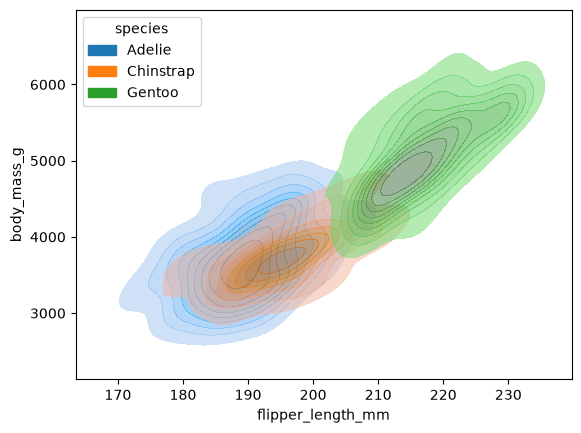

In [14]:
ax = sns.kdeplot(penguins, x='flipper_length_mm', y='body_mass_g', hue='species', 
                 fill=True, alpha=.5)
sns.move_legend(ax, loc="upper left")
plt.show()

**Answer**: In two dimensions the three species separate much more cleanly than they did on body mass alone.

Adelie and Chinstrap, which overlapped almost completely in Task 2, are now distinguished by flipper length.